# Stage 1 feature screening (before training)

This notebook screens **every column** in `question_b_feature_dictionary.csv` **before** any LightGBM or XGBoost model is trained, and saves a dataset containing only the columns that survive plus the few the modelling notebooks need to run.

`ac_load_kw` is the **target**: the value the models predict. It is not screened, because the checks exist to protect it. Every other column is a candidate input and must pass three checks.

| Check | Question it answers | Columns it excludes |
|---|---|---|
| **1. Leaky data** | Would the building manager have this at 00:00 on the day being forecast? | `split`, `ac_spike_flag`, `indoor_temp_out_of_range_flag`, `indoor_humidity_out_of_range_flag` |
| **2. Data quality** | Is the column populated, trustworthy, and present in every split? | `timestamp`, `month` |
| **3. Redundancy** | Can the column be reproduced from another column? | `floor`, `is_weekend`, `zone_id`, `zone`, `day_type`, `is_operating_hours`, `supply_air_sensor_flag` |

Each check runs on whatever survived the one before, so a column is excluded once, for the first reason that applies.

**Excluded as an input is not the same as deleted.** Five columns are excluded as model inputs but still written to the saved dataset, because the modelling notebooks need them to split, score and join the data. They are listed and justified in the final section.

**Why screen before training rather than let the model decide?**
- A leaky feature looks extremely important to the model and inflates accuracy, so importance scores after training would **reward** the very features that must be removed.
- A broken or duplicated feature still gets used by the trees. It dilutes the importance of the real signal, which makes Stage 2 harder to interpret.
- These checks don't need a model. They use the dictionary, the training data and simple statistics.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

DATA_DIR = Path("../cleaned_data")
OUT_DIR = Path("Output")
OUT_DIR.mkdir(exist_ok=True)

TARGET = "ac_load_kw"

# Screening thresholds
MAX_MISSING_PCT = 50       # Check 2a: exclude if more than this % of training rows is missing
MAX_UNCOVERED_PCT = 25     # Check 2c: exclude if more than this % of a split is outside what training saw
REDUNDANT_R = 0.90         # Check 3: |Spearman r| at or above this = redundant
CORRELATED_R = 0.70        # Check 3: |Spearman r| at or above this = shown as a correlated pair

# Columns compared by their set of values rather than by a min-max range in Check 2c.
# outdoor_humidity_* are stored as integers but are continuous measurements, so they are NOT here.
CATEGORICAL_LIKE = ["floor", "zone_code", "hour", "weekday", "month", "is_weekend", "is_holiday",
                    "zone_id", "zone", "day_type", "is_operating_hours", "supply_air_sensor_flag"]

## Load the data and list the candidate columns

Every column except the target is a candidate input. That includes the ids, the split label, the baseline's `day_type`, the reporting filter and the quality flags: if any of them is to be left out of the model, a check has to say why.

In [2]:
data = pd.read_parquet(DATA_DIR / "question_b_model_data.parquet")
dictionary = pd.read_csv(DATA_DIR / "question_b_feature_dictionary.csv")

ROLE = dictionary.set_index("column").role
CANDIDATES = [c for c in dictionary.column if c != TARGET]     # everything except the target

def _group(c):
    if ROLE[c] != "feature":
        return ROLE[c]                                          # id / split / baseline / filter / flag
    if c.startswith("indoor"):
        return "indoor"
    if c.startswith(("outdoor", "rainfall", "solar")):
        return "weather"
    if c.startswith("ac_load"):
        return "AC lag"
    return "calendar/zone"

GROUP = {c: _group(c) for c in CANDIDATES}

train = data[data.split.eq("train")]
train_op = train[train.is_operating_hours.eq(1)]          # working hours, where the AC actually runs

print(f"{len(data):,} rows | train {len(train):,} (operating hours {len(train_op):,})")
print(f"target: {TARGET} | {len(CANDIDATES)} candidate columns to screen")
display(pd.Series(GROUP).value_counts().to_frame("candidate columns"))

209,119 rows | train 111,779 (operating hours 31,037)
target: ac_load_kw | 34 candidate columns to screen


,candidate columns
weather,8
calendar/zone,7
indoor,6
flag,4
id,3
AC lag,3
split,1
baseline,1
filter,1


## Check 1: Leaky data

**What we check.** For every candidate column, would the building manager have its value at 00:00 on the day being forecast?

**Why this comes first.** A leaky column, measured during the hour being predicted, makes the model look far more accurate than it can ever be in use. Every later check is pointless if a leaky column is still in the set, and leakage is invisible to the later checks: a leaky column is not missing, not constant and not correlated with anything. It is the best-behaved column in the table.

**What it excludes**
- **`split`** does not exist for a future day at all. It is a label created for this experiment, not a property of the building.
- **`ac_spike_flag`** is computed from the target itself during the hour being predicted, so it would hand the model part of the answer.
- **`indoor_temp_out_of_range_flag`** and **`indoor_humidity_out_of_range_flag`** describe that hour's indoor sensor readings. The models only ever receive indoor values from yesterday or last week.

**A stated assumption.** Weather for the target hour (`outdoor_temp_hourly_c` and the other hourly weather columns) is **allowed**, standing in for a weather forecast. In real use these values would come from a forecast and carry some error, so the models here see slightly better weather information than they would in deployment.

The cell below also **checks that the lag columns really are lags**. It compares each one with the actual load the right number of hours earlier for the same zone. If they didn't match, a column might have been built from the wrong hour and could leak the answer.

In [3]:
LEAKY = {
    "split": "does not exist for a future day; a label for this experiment, not a property of the building",
    "ac_spike_flag": "computed from the target during the hour being predicted",
    "indoor_temp_out_of_range_flag": "describes this hour's indoor sensor, not known at 00:00",
    "indoor_humidity_out_of_range_flag": "describes this hour's indoor sensor, not known at 00:00",
}
check1 = pd.DataFrame({"column": CANDIDATES})
check1["group"] = [GROUP[c] for c in CANDIDATES]
check1["known_at_forecast_time"] = ["no" if c in LEAKY else "yes" for c in CANDIDATES]
check1["check1"] = ["exclude" if c in LEAKY else "pass" for c in CANDIDATES]
check1["reason"] = [LEAKY.get(c, "") for c in CANDIDATES]
display(check1[check1.check1.eq("exclude")].reset_index(drop=True))

AFTER_CHECK1 = [c for c in CANDIDATES if c not in LEAKY]
print(f"Check 1 excludes {len(LEAKY)}; {len(AFTER_CHECK1)} columns go on to Check 2\n")

# Verify the lags: compare each lag column with the real load shifted by the same number of hours
actual = data[["zone_id", "timestamp", TARGET]]
for col, hours in [("ac_load_kw_yesterday", 24), ("ac_load_kw_2_days_ago", 48), ("ac_load_kw_last_week", 168)]:
    shifted = actual.assign(timestamp=actual.timestamp + pd.Timedelta(hours=hours)).rename(columns={TARGET: "true_lag"})
    merged = data[["zone_id", "timestamp", col]].merge(shifted, on=["zone_id", "timestamp"]).dropna()
    match = np.isclose(merged[col], merged.true_lag, atol=1e-6).mean() * 100
    print(f"{col:<24} matches the load {hours:>3} h earlier on {match:.1f}% of {len(merged):,} comparable rows")

,column,group,known_at_forecast_time,check1,reason
0,split,split,no,exclude,does not exist for a future day; a label for t...
1,ac_spike_flag,flag,no,exclude,computed from the target during the hour being...
2,indoor_temp_out_of_range_flag,flag,no,exclude,"describes this hour's indoor sensor, not known..."
3,indoor_humidity_out_of_range_flag,flag,no,exclude,"describes this hour's indoor sensor, not known..."


Check 1 excludes 4; 30 columns go on to Check 2

ac_load_kw_yesterday     matches the load  24 h earlier on 100.0% of 207,261 comparable rows
ac_load_kw_2_days_ago    matches the load  48 h earlier on 100.0% of 205,965 comparable rows


ac_load_kw_last_week     matches the load 168 h earlier on 100.0% of 199,883 comparable rows


**Reading the result.** Four columns are excluded, and all four are genuine leaks in the sense that matters: their values would not be available when the forecast is issued. Nothing else in the dictionary has that problem, so every remaining column is available at 00:00.

Each lag matches the true load from the right number of hours earlier on 100% of comparable rows, so the lag columns are genuine and safe to use. Rows that can't be compared are those where the earlier hour is missing from the dataset, which is why the comparable count is below the full row count.

Note that `split` is excluded as an **input** but is still used throughout this notebook as machinery, to separate training from validation and test. The same is true of several other columns later: being excluded as a model input does not mean being deleted.

## Check 2: Data quality

**What we check.** Three things that make a column untrustworthy even when it isn't leaky:

- **2a. Missing values.** Tree models can handle gaps, but a mostly-empty column contributes little and mostly teaches the model "this value is missing". We also compare missingness **across splits**: a column that is complete in training but mostly missing in test would behave differently at test time.
- **2b. The Floor 5 zone 1 sensor.** This zone's temperature sensor sits in the AC supply air stream, so it measures cold air leaving the AC, not the room. We **mask** those readings rather than drop the zone, so the zone's AC load and other columns are still used. This is a fix, not an exclusion.
- **2c. Split coverage.** If validation or test contains values training never saw, the model can only guess for those rows.

**Why check quality before redundancy.** A broken column can look redundant with a working one for the wrong reason, so quality is settled first.

### 2a. Missing values by split

split,train,validation,test,max_gap_vs_train_pp
ac_load_kw_yesterday,0.8,0.4,1.5,0.7
ac_load_kw_2_days_ago,1.4,0.6,2.6,1.2
ac_load_kw_last_week,4.0,1.5,8.1,4.1
indoor_temp_c_yesterday,12.1,9.7,29.8,17.7
indoor_temp_c_last_week,15.0,9.2,29.9,14.9
indoor_temp_c_yesterday_avg,20.4,17.5,45.4,25.0
indoor_humidity_pct_yesterday,12.1,9.7,29.8,17.7
indoor_humidity_pct_last_week,15.0,9.2,29.9,14.9
indoor_humidity_pct_yesterday_avg,20.4,17.5,45.4,25.0


Excluded for missingness: none


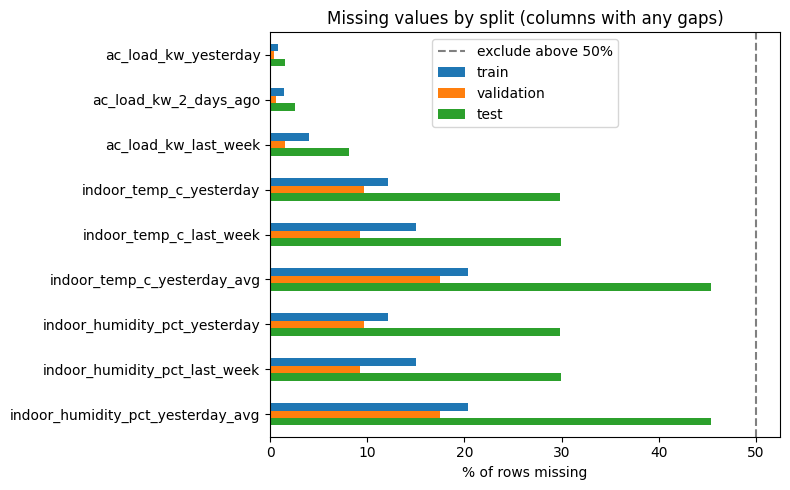

In [4]:
missing = (data.groupby("split")[AFTER_CHECK1].apply(lambda d: d.isna().mean() * 100).T
           [["train", "validation", "test"]].round(1))
missing["max_gap_vs_train_pp"] = (missing[["validation", "test"]].sub(missing.train, axis=0)).abs().max(axis=1)
display(missing[missing.train.gt(0) | missing.max_gap_vs_train_pp.gt(0)])

over_missing = missing.index[missing.train.gt(MAX_MISSING_PCT)].tolist()
print(f"Excluded for missingness: {over_missing if over_missing else 'none'}")

ax = missing[["train", "validation", "test"]].loc[lambda m: m.max(axis=1).gt(0)].plot.barh(figsize=(8, 5))
ax.axvline(MAX_MISSING_PCT, ls="--", c="grey", label=f"exclude above {MAX_MISSING_PCT}%")
ax.set(xlabel="% of rows missing", title="Missing values by split (columns with any gaps)")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

**Reading the result.**
- Only the lag features have gaps, and nothing comes close to the exclusion threshold in training, so **no column is excluded for missingness**. The model receives the gaps as missing values rather than filled-in guesses, because LightGBM and XGBoost learn their own handling of missing values.
- **The indoor lags are much patchier in the test period** (Jul-Sep 2018): about 30% missing for the hourly lags and 45% for the daily average, against 12-20% in training. The 2018 sensors had more outages. This doesn't justify excluding them, but it matters for the research question: **at test time the model often has to predict without indoor readings**, so whatever the indoor features contribute during training is unavailable for a large share of test rows. Keep this in mind when reading their importance later.

### 2b. Floor 5 zone 1: supply-air sensor

Zones carrying the supply-air flag: ['F5_Z1']


,F5_Z1 mean,F5_Z1 min,other zones mean,other zones min
indoor_temp_c_yesterday,23.7,11.0,25.1,16.1
indoor_temp_c_last_week,23.7,11.0,25.1,16.1
indoor_temp_c_yesterday_avg,23.8,19.5,25.0,19.4
indoor_humidity_pct_yesterday,69.0,47.0,65.4,37.5
indoor_humidity_pct_last_week,69.0,47.0,65.5,37.5
indoor_humidity_pct_yesterday_avg,69.0,49.3,65.5,39.7


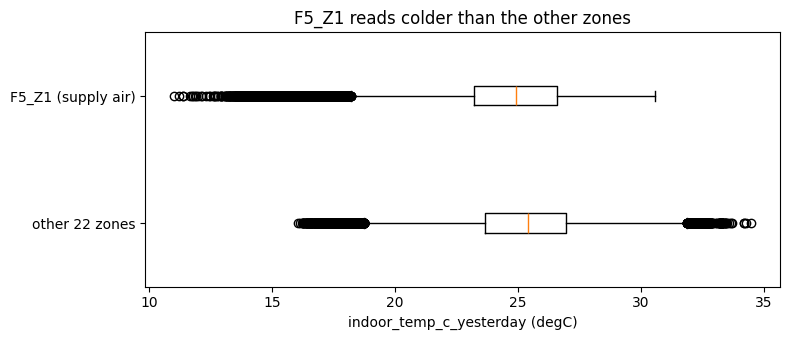

Masked ['indoor_temp_c_yesterday', 'indoor_temp_c_last_week', 'indoor_temp_c_yesterday_avg', 'indoor_humidity_pct_yesterday', 'indoor_humidity_pct_last_week', 'indoor_humidity_pct_yesterday_avg'] on 9,523 F5_Z1 rows


In [5]:
INDOOR = [c for c in AFTER_CHECK1 if GROUP[c] == "indoor"]
f5 = data.supply_air_sensor_flag.eq(1)
print("Zones carrying the supply-air flag:", data.loc[f5, "zone_id"].unique().tolist())

comparison = pd.DataFrame({
    "F5_Z1 mean": data.loc[f5, INDOOR].mean(), "F5_Z1 min": data.loc[f5, INDOOR].min(),
    "other zones mean": data.loc[~f5, INDOOR].mean(), "other zones min": data.loc[~f5, INDOOR].min(),
}).round(1)
display(comparison)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot([data.loc[~f5, "indoor_temp_c_yesterday"].dropna(), data.loc[f5, "indoor_temp_c_yesterday"].dropna()],
           tick_labels=["other 22 zones", "F5_Z1 (supply air)"], vert=False)
ax.set(xlabel="indoor_temp_c_yesterday (degC)", title="F5_Z1 reads colder than the other zones")
plt.tight_layout()
plt.show()

# Mask the indoor readings for this zone (temperature and humidity come from the same S1 sensor)
screened = data.copy()
screened.loc[f5, INDOOR] = np.nan
print(f"Masked {INDOOR} on {f5.sum():,} F5_Z1 rows")

# Every check from here on uses the masked training data
train_s = screened[screened.split.eq("train")]

**Reading the result.** F5_Z1 reads about 1.4 degC colder than the other zones on average, and drops to about 11 degC, well below the coldest reading anywhere else (about 16 degC) and below any comfortable room temperature. Its humidity comes from the same sensor, so both are masked. We keep the zone's rows: its AC load, AC lags, calendar and weather columns are all still valid.

From here on, every check uses the masked data (`screened`) and its training slice (`train_s`).

### 2c. Split coverage: values the training data never saw

In [6]:
def _fmt(v):
    """Format a range endpoint, whether it is a number or a timestamp."""
    return f"{v:.1f}" if isinstance(v, (int, float, np.integer, np.floating)) else str(v)

coverage = []
for c in AFTER_CHECK1:
    seen = train_s[c].dropna()
    for split in ["validation", "test"]:
        other = screened.loc[screened.split.eq(split), c].dropna()
        if c in CATEGORICAL_LIKE:
            unseen = sorted(set(other.unique()) - set(seen.unique()))
            pct = other.isin(unseen).mean() * 100
            detail = f"unseen values {unseen}" if unseen else ""
        else:
            pct = ((other < seen.min()) | (other > seen.max())).mean() * 100
            detail = f"outside train range {_fmt(seen.min())} to {_fmt(seen.max())}" if pct > 0 else ""
        coverage.append({"column": c, "split": split, "rows_not_covered_%": round(pct, 1), "detail": detail})

coverage = pd.DataFrame(coverage)
display(coverage[coverage["rows_not_covered_%"].gt(0)].reset_index(drop=True))

worst = coverage.groupby("column")["rows_not_covered_%"].max()
uncovered = worst.index[worst.gt(MAX_UNCOVERED_PCT)].tolist()

EXCLUDE_CHECK2 = {c: f"Check 2a: {missing.train[c]:.0f}% missing in training" for c in over_missing}
EXCLUDE_CHECK2.update({c: f"Check 2c: {worst[c]:.0f}% of a split outside what training saw"
                       for c in uncovered})
AFTER_CHECK2 = [c for c in AFTER_CHECK1 if c not in EXCLUDE_CHECK2]
print(f"Check 2 excludes {len(EXCLUDE_CHECK2)}: {list(EXCLUDE_CHECK2)}")
print(f"{len(AFTER_CHECK2)} columns go on to Check 3")

,column,split,rows_not_covered_%,detail
0,timestamp,validation,30.2,outside train range 2019-03-01 00:00:00 to 201...
1,timestamp,test,100.0,outside train range 2019-03-01 00:00:00 to 201...
2,month,validation,100.0,"unseen values [np.int32(4), np.int32(8), np.in..."
3,month,test,33.6,unseen values [np.int32(8)]
4,indoor_temp_c_yesterday_avg,validation,0.3,outside train range 19.4 to 31.7
5,indoor_humidity_pct_yesterday,validation,0.2,outside train range 41.8 to 87.9
6,indoor_humidity_pct_last_week,validation,0.4,outside train range 43.2 to 87.9
7,indoor_humidity_pct_yesterday_avg,validation,2.5,outside train range 49.9 to 82.0
8,outdoor_temp_hourly_c,validation,3.9,outside train range 22.1 to 38.8
9,outdoor_temp_daily_avg_c,validation,7.8,outside train range 25.6 to 32.9


Check 2 excludes 2: ['month', 'timestamp']
28 columns go on to Check 3


**Reading the result.** Two columns are above the threshold, and the gap to everything else is wide: the next highest is under 8%.

- **`timestamp`** is 100% uncovered on test. The test period is Jul-Sep 2018, entirely **before** every training timestamp, so no test row falls inside the trained range. A raw clock reading only ever increases, so a tree can only learn rules of the form "after this date, load is X", which is memorising the calendar rather than learning what drives load. Everything useful inside a timestamp is already unpacked into `hour`, `weekday`, `is_holiday` and the lags.
- **`month`** is 100% uncovered on validation. Training covers only Mar, May, Jun, Jul, Sep, Oct and Nov 2019, because April, August and December were set aside for validation. A tree can only lump months 4, 8 and 12 in with whichever trained months sit next to them, which is a guess. Seasonal effects are better carried by the weather columns and the AC lags, which are measured every day.

Everything else is a mild extrapolation at most: a few percent of weather or indoor values fall outside the training range, and trees handle that by treating the value like the nearest trained one. Those columns are kept.

## Check 3: Redundancy and correlation

**What we check.** Columns that carry information another column already holds, in two forms:
- **Fully determined.** The column can be reproduced exactly from one or more surviving columns. We test this by grouping on a **source block** and asking whether the column takes a single value within every group. Because the test counts distinct values rather than measuring correlation, it works on text as well as numbers, and it catches relationships that correlation misses entirely.
- **Highly correlated.** `|Spearman r|` at or above 0.90 between two columns.

**The two source blocks** are the primitive groupings in this dataset: `zone_code` (which zone a row belongs to) and the calendar triple `hour` + `weekday` + `is_holiday` (when the row occurs). Both survived Checks 1 and 2, which matters: a column should never be excluded by reference to one that was itself thrown out.

**Why a single-source test is not enough.** `day_type` and `is_operating_hours` are not determined by `hour` alone, or by `weekday` alone, or by `is_holiday` alone. They are determined by all three **together**. A pairwise test returns `False` for both and would let them through.

**Why it matters for tree models.** Trees don't break down when features are correlated, unlike linear regression, so accuracy is rarely the issue. The problems are:
- **Importance gets split.** If two columns say the same thing, the model uses each about half the time. Both then look half as important, and a real effect can appear weak in Stage 2.
- **Interpretation suffers.** The research question is whether indoor conditions and weather help. Redundant columns make it hard to say which group deserves the credit.

**Why Spearman.** It measures whether two columns rise and fall together, in a straight line or not, and is not thrown off by the long tail of zeros in AC load and rainfall, which would distort ordinary (Pearson) correlation.

Correlation runs on 26 numeric columns; ['zone_id', 'day_type'] are text and are covered by the determinism test instead.


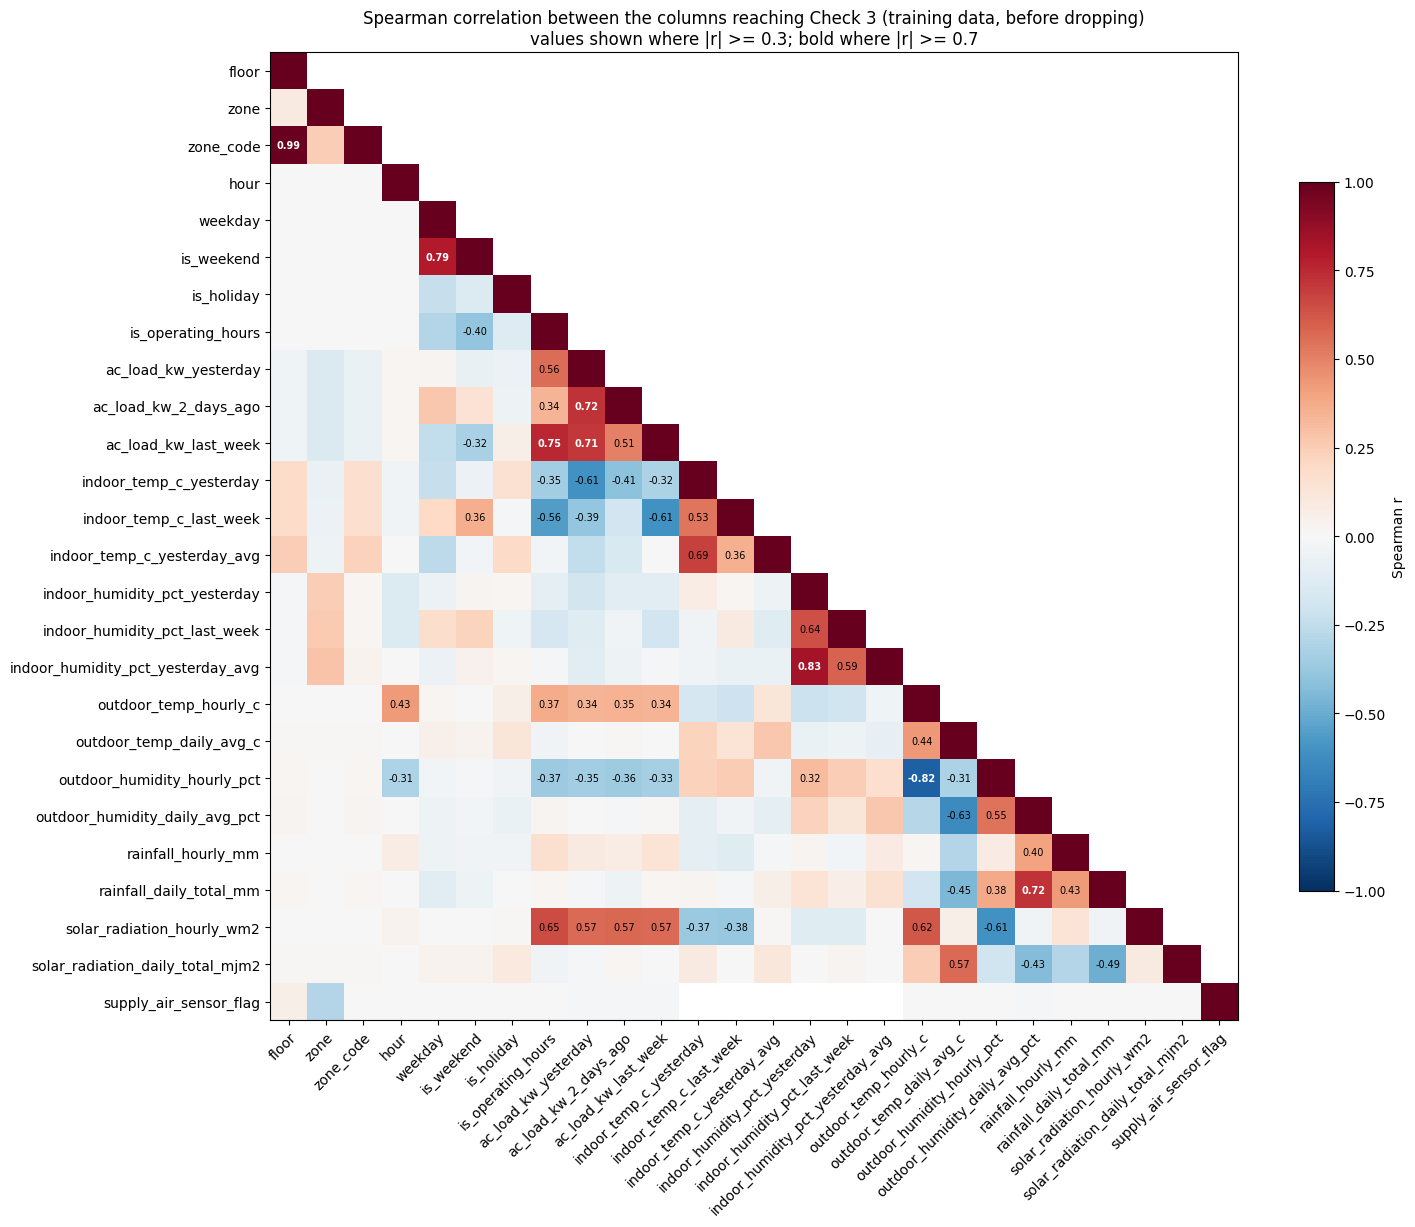

In [7]:
NUMERIC = [c for c in AFTER_CHECK2 if pd.api.types.is_numeric_dtype(screened[c])]
non_numeric = [c for c in AFTER_CHECK2 if c not in NUMERIC]
print(f"Correlation runs on {len(NUMERIC)} numeric columns; "
      f"{non_numeric} are text and are covered by the determinism test instead.")

corr = train_s[NUMERIC].corr(method="spearman")

fig, ax = plt.subplots(figsize=(15, 12.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)                  # show each pair once
img = ax.imshow(np.ma.masked_where(mask, corr), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)), NUMERIC, rotation=45, ha="right", rotation_mode="anchor")
ax.set_yticks(range(len(NUMERIC)), NUMERIC)
for i in range(len(NUMERIC)):
    for j in range(i + 1):
        r = corr.iat[i, j]
        if i != j and abs(r) >= 0.3:
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(r) >= 0.7 else "black",
                    fontweight="bold" if abs(r) >= CORRELATED_R else "normal")
fig.colorbar(img, ax=ax, shrink=0.7, label="Spearman r")
ax.set_title(f"Spearman correlation between the columns reaching Check 3 (training data, before dropping)\n"
             f"values shown where |r| >= 0.3; bold where |r| >= {CORRELATED_R}")
plt.tight_layout()
plt.show()

### Highly correlated pairs

In [8]:
target_r = train_s[NUMERIC + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = (upper.stack().rename("spearman_r").reset_index()
         .rename(columns={"level_0": "column_1", "level_1": "column_2"}))
pairs = pairs[pairs.spearman_r.abs().ge(CORRELATED_R)].sort_values("spearman_r", key=abs, ascending=False)
pairs["|r| with target (1 / 2)"] = [f"{abs(target_r[a]):.2f} / {abs(target_r[b]):.2f}"
                                    for a, b in zip(pairs.column_1, pairs.column_2)]
pairs["status"] = np.where(pairs.spearman_r.abs().ge(REDUNDANT_R), "redundant", "related, not a duplicate")
display(pairs.reset_index(drop=True))

,column_1,column_2,spearman_r,|r| with target (1 / 2),status
0,floor,zone_code,0.986514,0.05 / 0.06,redundant
1,indoor_humidity_pct_yesterday,indoor_humidity_pct_yesterday_avg,0.831249,0.11 / 0.02,"related, not a duplicate"
2,outdoor_temp_hourly_c,outdoor_humidity_hourly_pct,-0.818622,0.34 / 0.34,"related, not a duplicate"
3,weekday,is_weekend,0.794061,0.24 / 0.32,"related, not a duplicate"
4,is_operating_hours,ac_load_kw_last_week,0.752028,0.82 / 0.89,"related, not a duplicate"
5,outdoor_humidity_daily_avg_pct,rainfall_daily_total_mm,0.723840,0.00 / 0.01,"related, not a duplicate"
6,ac_load_kw_yesterday,ac_load_kw_2_days_ago,0.719882,0.72 / 0.50,"related, not a duplicate"
7,ac_load_kw_yesterday,ac_load_kw_last_week,0.706018,0.72 / 0.89,"related, not a duplicate"


### Columns fully determined by a source block, and columns mostly explained by time of day

In [9]:
SOURCE_BLOCKS = {"zone_code": ["zone_code"], "calendar": ["hour", "weekday", "is_holiday"]}
for name, cols in SOURCE_BLOCKS.items():
    assert all(c in AFTER_CHECK2 for c in cols), f"source block {name} uses an excluded column"

rows, EXCLUDE_CHECK3 = [], {}
for c in AFTER_CHECK2:
    for name, cols in SOURCE_BLOCKS.items():
        if c in cols:
            continue
        if train_s.groupby(cols, observed=True)[c].nunique().max() == 1:
            rows.append({"column": c, "determined_by": name, "source columns": " + ".join(cols)})
            EXCLUDE_CHECK3[c] = f"Check 3: fully determined by {' + '.join(cols)}"
            break
display(pd.DataFrame(rows))

AFTER_CHECK3 = [c for c in AFTER_CHECK2 if c not in EXCLUDE_CHECK3]
still_redundant = pairs[pairs.spearman_r.abs().ge(REDUNDANT_R)
                        & ~pairs.column_1.isin(EXCLUDE_CHECK3) & ~pairs.column_2.isin(EXCLUDE_CHECK3)]
print(f"Check 3 excludes {len(EXCLUDE_CHECK3)}: {list(EXCLUDE_CHECK3)}")
print(f"Pairs at |r| >= {REDUNDANT_R} not already handled by the determinism test: {len(still_redundant)}")
print(f"{len(AFTER_CHECK3)} columns survive all three checks")

def share_explained_by_hour(col):
    s = train_s[col]
    return 1 - ((s - s.groupby(train_s.hour).transform("mean")) ** 2).sum() / ((s - s.mean()) ** 2).sum()

by_hour = pd.Series({c: share_explained_by_hour(c) for c in AFTER_CHECK3
                     if GROUP[c] == "weather"}).sort_values(ascending=False)
display((100 * by_hour).round(1).to_frame("% of variation explained by hour of day"))

,column,determined_by,source columns
0,zone_id,zone_code,zone_code
1,floor,zone_code,zone_code
2,zone,zone_code,zone_code
3,is_weekend,calendar,hour + weekday + is_holiday
4,day_type,calendar,hour + weekday + is_holiday
5,is_operating_hours,calendar,hour + weekday + is_holiday
6,supply_air_sensor_flag,zone_code,zone_code


Check 3 excludes 7: ['zone_id', 'floor', 'zone', 'is_weekend', 'day_type', 'is_operating_hours', 'supply_air_sensor_flag']
Pairs at |r| >= 0.9 not already handled by the determinism test: 0
21 columns survive all three checks


,% of variation explained by hour of day
solar_radiation_hourly_wm2,90.3
outdoor_temp_hourly_c,66.2
outdoor_humidity_hourly_pct,51.8
rainfall_hourly_mm,3.2
solar_radiation_daily_total_mjm2,0.0
outdoor_humidity_daily_avg_pct,0.0
outdoor_temp_daily_avg_c,0.0
rainfall_daily_total_mm,0.0


**Reading the results.**

- **Determined by `zone_code`:** `zone_id`, `zone`, `floor` and `supply_air_sensor_flag`. Each zone sits on exactly one floor and carries exactly one zone number, so `zone_code` already holds all of it; `zone_code` stays because it is the finest of them. `supply_air_sensor_flag` is 1 for exactly one zone, so as an input it would only repeat that zone's identity — its real job was to drive the masking in Check 2b, which has already happened.
- **Determined by the calendar triple:** `day_type`, `is_weekend` and `is_operating_hours`. `is_weekend` is `weekday >= 5`; `day_type` is weekday/weekend/holiday; `is_operating_hours` is 07:00-17:00 on non-holiday weekdays. A tree reproduces each from the three calendar columns it already has.
- **`is_operating_hours` deserves a note.** It is the single strongest column in the dataset after the lags: mean load is 15.4 kW inside operating hours and 0.6 kW outside, a 28x difference. As an input it would dominate every importance ranking and the study of whether indoor conditions and weather help would be answered by a column that just says when the AC is switched on. It is excluded here as redundant, and kept in the saved data for a different purpose: choosing which rows get scored.
- **`is_holiday` is not determined by anything** and stays. Holidays fall on any weekday and cannot be derived from the calendar columns.
- **Correlated pairs between 0.70 and 0.90** are related but not duplicates, so both columns are kept: the AC lags overlap because the building repeats its weekly pattern but each catches different disruptions; hot hours are drier; wet days are humid.
- **Hourly solar radiation** is about 90% explained by hour of day: sunlight follows the clock. It is kept, because the remaining 10% is the weather (cloud cover). When reading its importance later, remember that much of it may be the daily pattern rather than the weather.

## Decision: keep, exclude, or target

Every column in the dictionary appears below exactly once, with the check that decided its fate.

Read the two columns separately:
- **`decision`** answers *"is this a model input?"* Only `keep` columns are given to LightGBM and XGBoost.
- **`in_screened_file`** answers *"is this written to the saved dataset?"* Five excluded columns are still saved, because the modelling notebooks need them. The next section explains each one.

In [10]:
ESSENTIAL = ["zone_id", "timestamp", "split", "is_operating_hours", TARGET]
KEPT = AFTER_CHECK3

REASONS = {TARGET: "the value being predicted; the checks exist to protect it"}
REASONS.update({c: f"Check 1: {r}" for c, r in LEAKY.items()})
REASONS.update(EXCLUDE_CHECK2)
REASONS.update(EXCLUDE_CHECK3)

decision = pd.DataFrame({
    "column": dictionary.column,
    "group": [GROUP.get(c, "target") for c in dictionary.column],
    "decision": [("target" if c == TARGET else "keep" if c in KEPT else "exclude")
                 for c in dictionary.column],
    "reason": [REASONS.get(c, "passed all three checks") for c in dictionary.column],
    "in_screened_file": ["yes" if c in ESSENTIAL or c in KEPT else "no" for c in dictionary.column],
}).set_index("column")

assert len(decision) == len(dictionary), "every column must appear exactly once"
assert set(decision.index[decision.decision.eq("keep")]) == set(KEPT)

display(decision.style.map(lambda v: {"exclude": "color: #C44E52; font-weight: bold",
                                      "target": "color: #4C72B0; font-weight: bold"}.get(v, ""),
                           subset=["decision"]))
print(decision.decision.value_counts().to_string())
print(f"\nWritten to the saved dataset: {(decision.in_screened_file == 'yes').sum()} columns "
      f"({len(ESSENTIAL)} needed to run the models + {len(KEPT)} features)")

,group,decision,reason,in_screened_file
column,,,,
zone_id,id,exclude,Check 3: fully determined by zone_code,yes
floor,calendar/zone,exclude,Check 3: fully determined by zone_code,no
zone,id,exclude,Check 3: fully determined by zone_code,no
zone_code,calendar/zone,keep,passed all three checks,yes
timestamp,id,exclude,Check 2c: 100% of a split outside what training saw,yes
split,split,exclude,"Check 1: does not exist for a future day; a label for this experiment, not a property of the building",yes
ac_load_kw,target,target,the value being predicted; the checks exist to protect it,yes
hour,calendar/zone,keep,passed all three checks,yes
weekday,calendar/zone,keep,passed all three checks,yes


decision
keep       21
exclude    13
target      1

Written to the saved dataset: 26 columns (5 needed to run the models + 21 features)


## The five columns that are excluded but still saved

These are excluded as **model inputs** by the checks above, yet the modelling notebook cannot run without them. Dropping them from the file would break `LightGBM.ipynb`.

| Column | Excluded by | Why the saved file still needs it |
|---|---|---|
| `split` | Check 1 | Splits the data: `train = df[df.split == "train"]`, and the validation, full and test slices. The first thing the modelling notebook does. |
| `timestamp` | Check 2c | Half of the composite key. Predictions are merged back onto actuals and baselines with `on=["zone_id", "timestamp"]`, and it orders the time-series plots. |
| `zone_id` | Check 3 | The other half of that key. It also builds the `zone_id -> zone_code` map in `ac_forecaster.py`, so a saved model can be given a readable zone name like `F5_Z1`. |
| `is_operating_hours` | Check 3 | Chooses which rows are scored. Headline accuracy is reported on working hours (`OP_VALID = valid.is_operating_hours.eq(1)`). Excluded as an input precisely so the model cannot use it, then used to evaluate the model. |
| `ac_load_kw` | target | The value being predicted. Needed to train and to score. |

`day_type` is **not** in this list. It is the input to baseline B2, but `Baselines.ipynb` reads the unscreened `question_b_model_data.parquet`, so nothing that reads the screened file uses it.

**The saved dictionary distinguishes the two meanings of "kept".** `stage1_decision` is `keep` only for the model inputs, which is what `LightGBM.ipynb` filters on (`fdict["stage1_decision"].eq("keep")`). The five columns above are `exclude` or `target` there, and `in_screened_file` records that they are saved anyway. If they were labelled `keep`, the model would be handed the join keys and the target itself.

In [11]:
screened_out = screened[ESSENTIAL + KEPT]
screened_out.to_parquet(OUT_DIR / "question_b_model_data_screened.parquet", index=False)

dict_out = dictionary.copy()
dict_out["stage1_decision"] = [decision.decision[c] for c in dict_out.column]
dict_out["stage1_reason"] = [decision.reason[c] for c in dict_out.column]
dict_out["in_screened_file"] = [decision.in_screened_file[c] for c in dict_out.column]
dict_out.loc[~dict_out.column.isin(KEPT), ["M1", "M2", "M3", "M4"]] = np.nan
dict_out.to_csv(OUT_DIR / "question_b_feature_dictionary_screened.csv", index=False)

# The modelling notebook reads its feature list straight from stage1_decision, so guard it here.
assert dict_out.loc[dict_out.stage1_decision.eq("keep"), "column"].tolist() == KEPT
assert TARGET not in KEPT and not set(ESSENTIAL) & set(KEPT)

print(f"Excluded as model inputs: {len(decision) - len(KEPT) - 1} columns, plus the target")
print(f"Kept as model inputs    : {len(KEPT)}")
print(f"Saved {screened_out.shape[0]:,} rows x {screened_out.shape[1]} columns "
      f"({len(ESSENTIAL)} needed to run the model + {len(KEPT)} features)")
print("\nFeatures in the full model, by group:")
print(pd.Series({c: GROUP[c] for c in KEPT}).value_counts().to_string())

Excluded as model inputs: 13 columns, plus the target
Kept as model inputs    : 21
Saved 209,119 rows x 26 columns (5 needed to run the model + 21 features)

Features in the full model, by group:
weather          8
indoor           6
calendar/zone    4
AC lag           3
